In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten
import random
import numpy as np
from keras.datasets import mnist

C:\Users\Sanika\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train=x_train/255
x_test=x_test/255
x_train.shape

(60000, 28, 28)

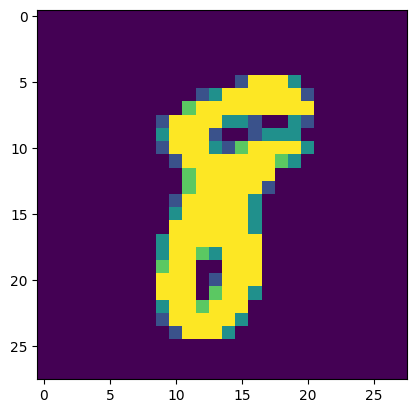

In [3]:
idx = random.randint(0, len(x_train))
plt.imshow(x_train[idx, :])
plt.show()

In [4]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),

    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

C:\Users\Sanika\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model = Sequential()

model.add(Conv2D(32, (3,3), activation = 'relu', input_shape = (28,28, 1)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(32, (3,3), activation = 'relu'))
model.add(MaxPooling2D((2,2)))

model.add(Flatten())
model.add(Dense(64, activation = 'relu'))
model.add(Dense(10, activation = 'softmax'))

In [9]:
model.compile(optimizer='sgd',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
H=model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=3)


Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 12ms/step - accuracy: 0.8374 - loss: 0.5334 - val_accuracy: 0.9464 - val_loss: 0.1818
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9557 - loss: 0.1486 - val_accuracy: 0.9686 - val_loss: 0.1021
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 42s 12ms/step - accuracy: 0.9678 - loss: 0.1044 - val_accuracy: 0.9709 - val_loss: 0.0887


In [12]:
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9709 - loss: 0.0887


[0.0887179896235466, 0.9708999991416931]

In [ ]:
model.evaluate(x_test, y_test)

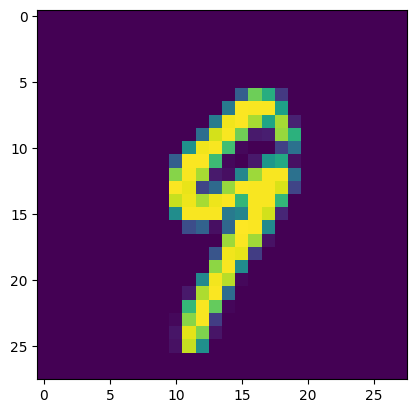

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
The handwritten number in image is 9


In [13]:
n=random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()
prediction=model.predict(x_test)
print("The handwritten number in image is %d" %np.argmax(prediction[n]))

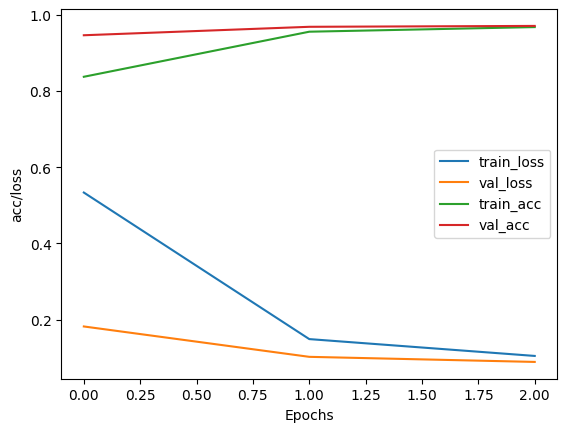

In [14]:
plt.plot(H.history['loss'],label='train_loss')
plt.plot(H.history['val_loss'],label='val_loss')
plt.plot(H.history['accuracy'],label='train_acc')
plt.plot(H.history['val_accuracy'],label='val_acc')
plt.xlabel('Epochs')
plt.ylabel('acc/loss')
plt.legend()
plt.show()